In [6]:
import sys
import os

import numpy as np
from hcipy import *
import matplotlib.pyplot as plt

import matplotlib.pylab as pylab
params = {'legend.fontsize': 'x-large',
          'figure.figsize': (12, 5),
         'axes.labelsize': 'large',
         'axes.titlesize':'large',
         'xtick.labelsize':'medium',
         'ytick.labelsize':'medium',
         'font.family':'serif'}
pylab.rcParams.update(params)


sys.path.append(os.path.abspath(os.path.join(os.path.dirname('adc_sims'), '..')))

from adcFitter_onsky import AdcFitter

In [7]:
#fields = read_field('/Users/Katie/Documents/Fall 2023/MagAO-X/ADC Sim code/updated onsky/all_filtered_fields.fits')

before = read_fits('/Users/Katie/Documents/MagAO-X/Data/ADC/2025A/2025-04-15_043943_alfcen_closed_loop_iz/camsci1/camsci1_20250415044026224307141.fits')
after = read_fits('/Users/Katie/Documents/MagAO-X/Data/ADC/2025A/2025-04-15_043943_alfcen_closed_loop_iz/camsci1/camsci1_20250415044414314915532.fits')

print(before.size)

262144


In [13]:
#convert the images into fields with the correct dimensions
img = before
dim = np.sqrt(img.size)
extent = dim * 6/21
pgrid = make_pupil_grid(dim,extent)
img = Field(img.ravel(),pgrid)

before = Field(before.ravel(),pgrid)
after = Field(after.ravel(),pgrid)

In [16]:
#system params
wavelength = 764E-9
bw = 120E-9
grating_angle = 28
grating_freq = 47

ADC = AdcFitter(wavelength=wavelength,grating_freq=grating_freq,grating_angle=grating_angle)
before = ADC.crop_image(before,extent=400,mask_diam=0)
after = ADC.crop_image(after,extent=400,mask_diam=0)

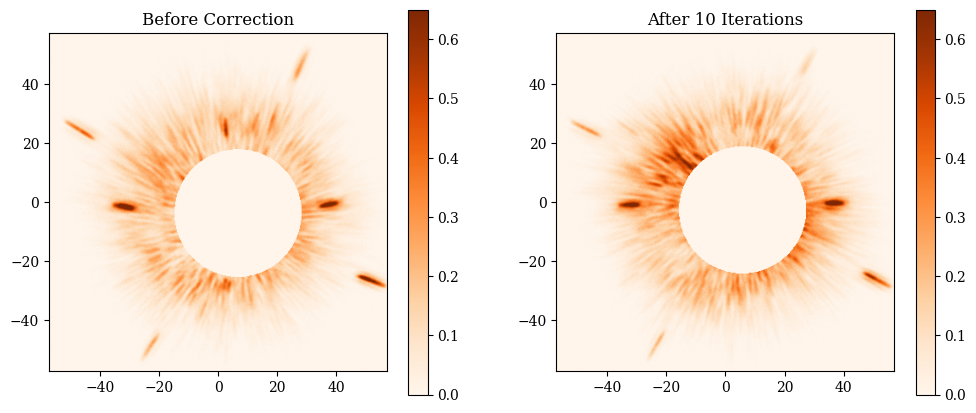

In [18]:
color = 'Oranges'

fig = plt.figure()
plt.subplot(1,2,1)
imshow_field(before,cmap=color,vmax=0.65)
plt.colorbar()
plt.title('Before Correction')
plt.subplot(1,2,2)
imshow_field(after,cmap=color,vmax=0.65)
plt.colorbar()
plt.title('After 10 Iterations')
#plt.tight_layout()
plt.show()

In [19]:
fig.savefig('/Users/Katie/Documents/MagAO-X/figures/ADC/summer school poster/before_after.png',dpi=300)